In [1]:
# Ścieżka do repo (notebook leży w notebooks/, kod w src/)
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
print('Repo:', REPO_ROOT)

Repo: C:\Users\tomek\Desktop\Uczelnia\PG\VII Sem\DNN\dnn\plant-pathology


In [2]:
# Installation and Imports
import os
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, multilabel_confusion_matrix, confusion_matrix, f1_score,
                             precision_score, recall_score, accuracy_score)
from PIL import Image

# Set random seeds for reproducibility
RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed_all(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")

Libraries imported successfully!
PyTorch version: 2.15.0+cpu
CUDA available: False


In [3]:
# Configuration (ścieżki i stałe pochodzą z src/config.py)
from src import config as C


class Config:
    # Dane (lokalnie w <repo>/data, patrz README)
    DATA_DIR = C.DATA_DIR
    TRAIN_CSV = str(C.TRAIN_CSV)
    IMAGES_DIR = str(C.IMAGES_DIR) + os.sep  # load_and_split_data dokleja nazwę pliku

    # Model
    INPUT_HEIGHT = C.INPUT_HEIGHT
    INPUT_WIDTH = C.INPUT_WIDTH
    BATCH_SIZE = C.DEFAULT_HPARAMS['batch_size']
    NUM_WORKERS = C.DEFAULT_HPARAMS['num_workers']

    # Normalizacja (ImageNet)
    IMAGENET_MEAN = C.IMAGENET_MEAN
    IMAGENET_STD = C.IMAGENET_STD

    # Klasy
    LABELS = C.LABELS
    NUM_CLASSES = C.NUM_CLASSES

    # Trening
    NUM_EPOCHS = C.DEFAULT_HPARAMS['num_epochs']
    LEARNING_RATE = C.DEFAULT_HPARAMS['learning_rate']
    WEIGHT_DECAY = C.DEFAULT_HPARAMS['weight_decay']
    PATIENCE = C.DEFAULT_HPARAMS['patience']

    DEVICE = C.DEVICE

    # Wyniki
    OUTPUT_DIR = C.OUTPUT_DIR
    CHECKPOINT_DIR = C.CHECKPOINT_DIR
    PLOT_DIR = C.PLOT_DIR
    METRICS_DIR = C.METRICS_DIR

    @classmethod
    def create_dirs(cls):
        for d in (cls.OUTPUT_DIR, cls.CHECKPOINT_DIR, cls.PLOT_DIR, cls.METRICS_DIR):
            d.mkdir(parents=True, exist_ok=True)


Config.create_dirs()
config = Config()

assert os.path.exists(config.TRAIN_CSV), f"Brak {config.TRAIN_CSV} - wypakuj dane do folderu data/ (README)"
print("Configuration loaded successfully!")
print(f"Device: {config.DEVICE}")
print(f"Data: {config.DATA_DIR}")
print(f"Output directory: {config.OUTPUT_DIR}")

Configuration loaded successfully!
Device: cpu
Data: C:\Users\tomek\Desktop\Uczelnia\PG\VII Sem\DNN\dnn\plant-pathology\data
Output directory: C:\Users\tomek\Desktop\Uczelnia\PG\VII Sem\DNN\dnn\plant-pathology\baseline_outputs


In [4]:
# Data Loading and Splitting
def load_and_split_data(csv_path: Path, train_size: float = 0.7,
                        val_size: float = 0.15, test_size: float = 0.15,
                        random_state: int = 42):
    """
    Load CSV and split into train/validation/test sets.
    
    Args:
        csv_path: Path to CSV file
        train_size: Proportion of training data
        val_size: Proportion of validation data
        test_size: Proportion of test data
        random_state: Random seed for reproducibility
    
    Returns:
        train_df, val_df, test_df: DataFrames with image paths and labels
    """
    # Load CSV
    df = pd.read_csv(csv_path)

    # Update image paths to point to local data directory
    df['image'] = df['image'].apply(lambda x: config.IMAGES_DIR + x)

    # First split: train vs (val + test)
    train_df, temp_df = train_test_split(
        df, train_size=train_size, shuffle=True, random_state=random_state
    )

    # Second split: val vs test
    val_ratio = val_size / (val_size + test_size)
    val_df, test_df = train_test_split(
        temp_df, train_size=val_ratio, shuffle=True, random_state=random_state
    )

    print(f"Dataset split complete:")
    print(f"  Train: {len(train_df)} samples")
    print(f"  Validation: {len(val_df)} samples")
    print(f"  Test: {len(test_df)} samples")

    return train_df, val_df, test_df


# Load and split data
train_df, val_df, test_df = load_and_split_data(config.TRAIN_CSV)

Dataset split complete:
  Train: 13042 samples
  Validation: 2795 samples
  Test: 2795 samples


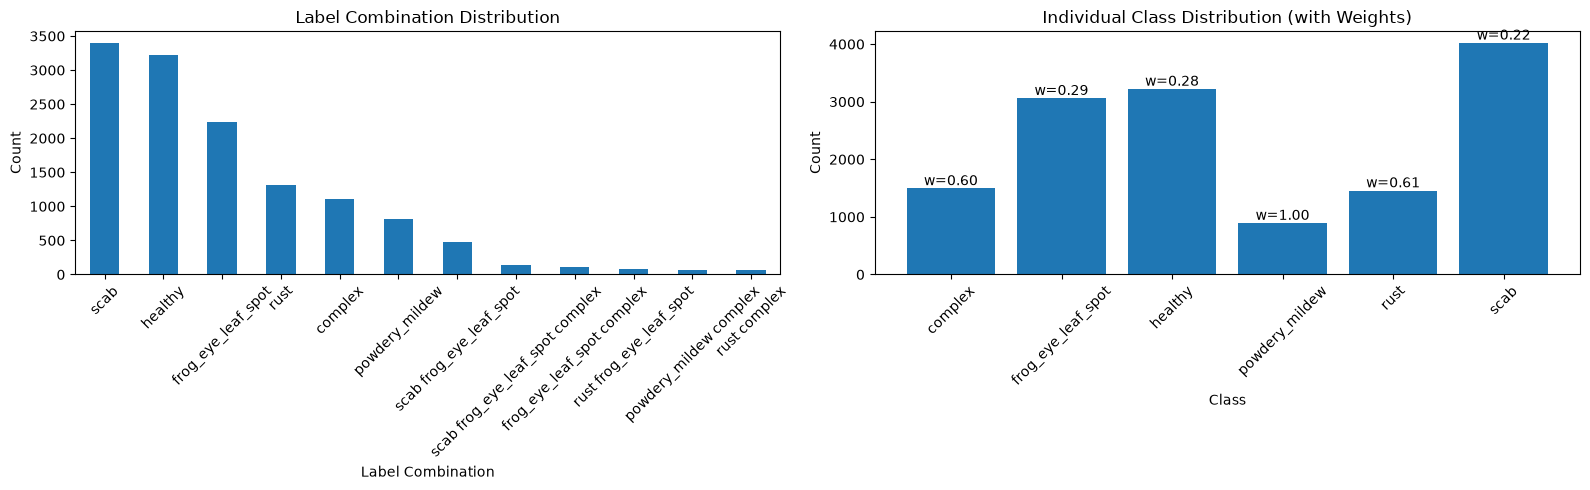


Class Statistics:
--------------------------------------------------
complex                  : Count=1493 | Weight=0.5968
frog_eye_leaf_spot       : Count=3059 | Weight=0.2913
healthy                  : Count=3220 | Weight=0.2767
powdery_mildew           : Count= 891 | Weight=1.0000
rust                     : Count=1456 | Weight=0.6120
scab                     : Count=4021 | Weight=0.2216


In [5]:
# Analyze Class Distribution
def analyze_class_distribution(train_df: pd.DataFrame):
    """
    Analyze and visualize class distribution in the training set.
    
    Args:
        train_df: Training DataFrame with 'labels' column
    """
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # Plot 1: Label combination distribution
    train_df['labels'].value_counts().plot(kind='bar', ax=axes[0])
    axes[0].set_title('Label Combination Distribution')
    axes[0].set_xlabel('Label Combination')
    axes[0].set_ylabel('Count')
    axes[0].tick_params(axis='x', rotation=45)

    # Plot 2: Individual class distribution
    all_labels = train_df['labels'].str.split(expand=True).stack().reset_index(drop=True)
    class_counts = all_labels.value_counts()[config.LABELS]

    # Calculate class weights (inverse frequency)
    class_weights = torch.reciprocal(torch.tensor(class_counts.values, dtype=torch.float))
    class_weights = class_weights / torch.max(class_weights)

    # Plot bar chart
    bars = axes[1].bar(class_counts.index, class_counts.values)
    axes[1].set_title('Individual Class Distribution (with Weights)')
    axes[1].set_xlabel('Class')
    axes[1].set_ylabel('Count')
    axes[1].tick_params(axis='x', rotation=45)

    # Add weight annotations on bars
    for bar, weight in zip(bars, class_weights):
        height = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width() / 2., height,
                     f'w={weight:.2f}',
                     ha='center', va='bottom', fontsize=10)

    plt.tight_layout()
    plt.savefig(config.PLOT_DIR / 'class_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Print statistics
    print("\nClass Statistics:")
    print("-" * 50)
    for label, count, weight in zip(class_counts.index, class_counts.values, class_weights):
        print(f"{label:25s}: Count={count:4d} | Weight={weight:.4f}")

    return class_counts, class_weights


# Analyze distribution
class_counts, class_weights = analyze_class_distribution(train_df)

In [6]:
# Data Augmentation and Preprocessing (definicje w src/transforms.py)
from src.transforms import get_train_transforms, get_val_transforms

train_transforms = get_train_transforms()
val_transforms = get_val_transforms()

print("Training transforms:\n", train_transforms)
print("\nValidation transforms:\n", val_transforms)

Training transforms:
 Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-30.0, 30.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation transforms:
 Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [7]:
# Dataset and DataLoader (PlantDataset w src/dataset.py)
from src.dataset import PlantDataset

train_dataset = PlantDataset(train_df, transform=train_transforms)
val_dataset = PlantDataset(val_df, transform=val_transforms)
test_dataset = PlantDataset(test_df, transform=val_transforms)

pin = config.DEVICE == 'cuda'
train_loader = DataLoader(train_dataset, batch_size=config.BATCH_SIZE, shuffle=True,
                          num_workers=config.NUM_WORKERS, pin_memory=pin)
val_loader = DataLoader(val_dataset, batch_size=config.BATCH_SIZE, shuffle=False,
                        num_workers=config.NUM_WORKERS, pin_memory=pin)
test_loader = DataLoader(test_dataset, batch_size=config.BATCH_SIZE, shuffle=False,
                         num_workers=config.NUM_WORKERS, pin_memory=pin)

print("Datasets and DataLoaders created!")
print(f"Train batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

Datasets and DataLoaders created!
Train batches: 408
Validation batches: 88
Test batches: 88


In [8]:
# Model Architecture: CustomPlantCNN (definicja w src/model.py)
from src.model import CustomPlantCNN

model = CustomPlantCNN(num_classes=config.NUM_CLASSES).to(config.DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("CustomPlantCNN initialized!")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(model)

CustomPlantCNN initialized!
Total parameters: 4,908,870
Trainable parameters: 4,908,870
CustomPlantCNN(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): SimpleResBlock(
    (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (shortcut): Sequential()
  )
  (layer2): SimpleResBlock(
    (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, 

In [9]:
# Loss Function with Class Weighting
criterion = nn.BCEWithLogitsLoss(pos_weight=class_weights.to(config.DEVICE))

# Optimizer: AdamW (Adam with decoupled weight decay)
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=config.LEARNING_RATE,
    weight_decay=config.WEIGHT_DECAY
)

# Learning Rate Scheduler: ReduceLROnPlateau
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',  # Minimize validation loss
    factor=0.1,  # Reduce LR by factor of 10
    patience=config.PATIENCE,  # Wait 3 epochs before reducing
    threshold=1e-4
)

print("Training components configured:")
print(f"  Loss: BCEWithLogitsLoss with pos_weight")
print(f"  Optimizer: AdamW (lr={config.LEARNING_RATE}, weight_decay={config.WEIGHT_DECAY})")
print(f"  Scheduler: ReduceLROnPlateau (patience={config.PATIENCE}, factor=0.1)")

Training components configured:
  Loss: BCEWithLogitsLoss with pos_weight
  Optimizer: AdamW (lr=0.001, weight_decay=0.0001)
  Scheduler: ReduceLROnPlateau (patience=3, factor=0.1)


In [10]:
# Training and Evaluation Functions
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    """
    Train model for one epoch.
    
    Args:
        model: Neural network model
        dataloader: Training data loader
        criterion: Loss function
        optimizer: Optimizer
        device: Device to train on
    
    Returns:
        avg_loss: Average training loss
        avg_acc: Average training accuracy (element-wise for multi-label)
        avg_f1: Average training F1 score (macro, better metric for multi-label)
    """
    model.train()
    running_loss = 0.0
    running_correct = 0
    total_preds = 0
    total_samples = 0

    all_preds_list = []
    all_labels_list = []

    progress_bar = tqdm(dataloader, desc='Training', leave=False)

    for images, labels in progress_bar:
        images, labels = images.to(device), labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Statistics
        batch_size = images.size(0)
        running_loss += loss.item() * batch_size
        total_samples += batch_size

        # Calculate element-wise accuracy (each label prediction counts separately)
        preds = (torch.sigmoid(outputs) > 0.5).float()
        running_correct += (preds == labels).float().sum()
        total_preds += labels.numel()  # Total number of individual label predictions

        # Store for F1 calculation
        all_preds_list.append(preds.cpu().numpy())
        all_labels_list.append(labels.cpu().numpy())

        # Update progress bar
        progress_bar.set_postfix({
            'loss': f'{loss.item():.4f}',
            'acc': f'{(preds == labels).float().mean().item():.4f}'
        })

    avg_loss = running_loss / total_samples
    avg_acc = running_correct / total_preds

    # Calculate macro F1 score (better metric for multi-label)
    all_preds = np.vstack(all_preds_list)
    all_labels = np.vstack(all_labels_list)
    avg_f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)

    return avg_loss, avg_acc, avg_f1


def validate(model, dataloader, criterion, device, return_probs=False):
    """
    Validate model on validation set.
    
    Args:
        model: Neural network model
        dataloader: Validation data loader
        criterion: Loss function
        device: Device to validate on
        return_probs: If True, return probabilities along with binary predictions
    
    Returns:
        avg_loss: Average validation loss
        avg_acc: Average validation accuracy (element-wise for multi-label)
        avg_f1: Average validation F1 score (macro)
        all_preds: All predictions (numpy array)
        all_labels: All true labels (numpy array)
        all_probs: All probabilities (numpy array) - only if return_probs=True
    """
    model.eval()
    running_loss = 0.0
    running_correct = 0
    total_preds = 0
    total_samples = 0

    all_preds = []
    all_labels = []
    all_probs = []  # Store probabilities if requested

    with torch.no_grad():
        for images, labels in tqdm(dataloader, desc='Validation', leave=False):
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Statistics
            batch_size = images.size(0)
            running_loss += loss.item() * batch_size
            total_samples += batch_size

            # Predictions - get probabilities FIRST
            probs = torch.sigmoid(outputs)
            preds = (probs > 0.5).float()

            # Store for later analysis
            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.cpu().numpy())
            if return_probs:
                all_probs.append(probs.cpu().numpy())  # Save probabilities

            # Element-wise accuracy (each label prediction counts separately)
            running_correct += (preds == labels).float().sum()
            total_preds += labels.numel()

    avg_loss = running_loss / total_samples
    avg_acc = running_correct / total_preds

    # Calculate macro F1 score (better metric for multi-label)
    all_preds_np = np.vstack(all_preds)
    all_labels_np = np.vstack(all_labels)
    avg_f1 = f1_score(all_labels_np, all_preds_np, average='macro', zero_division=0)

    if return_probs:
        all_probs = np.vstack(all_probs)
        return avg_loss, avg_acc, avg_f1, all_preds_np, all_labels_np, all_probs
    else:
        return avg_loss, avg_acc, avg_f1, all_preds_np, all_labels_np


print("Training and evaluation functions defined!")
print("\n⚠️  NOTE: Accuracy in multi-label classification can be misleading!")
print("   - Element-wise accuracy: Includes correct negative predictions (easy)")
print("   - F1 score: Balances precision & recall (better metric for imbalanced data)")
print("   - We track BOTH to monitor training properly")

Training and evaluation functions defined!

⚠️  NOTE: Accuracy in multi-label classification can be misleading!
   - Element-wise accuracy: Includes correct negative predictions (easy)
   - F1 score: Balances precision & recall (better metric for imbalanced data)
   - We track BOTH to monitor training properly


## Training Loop

The model will be trained for **30 epochs** with the following protocol:

1. **Forward pass**: Compute logits for each batch
2. **Loss calculation**: BCEWithLogitsLoss with class-weighted positives
3. **Backward pass**: Compute gradients via backpropagation
4. **Optimizer step**: Update parameters via AdamW
5. **Validation**: Evaluate on validation set after each epoch
6. **Learning rate scheduling**: Reduce LR if validation loss plateaus
7. **Checkpointing**: Save best model based on validation loss

### Key Metrics Tracked:
- **Training Loss**: BCE loss on training batches
- **Training Accuracy**: Exact match accuracy (all labels correct)
- **Validation Loss**: BCE loss on validation set
- **Validation Accuracy**: Exact match accuracy on validation set
- **Learning Rate**: Current learning rate after scheduling

In [11]:
# Training Loop z checkpointingiem i wznawianiem
from src.checkpoint import save_checkpoint, resume_from_checkpoint

# Osoba A może zdefiniować własny słownik `hparams` wcześniej w notebooku
if 'hparams' not in globals():
    hparams = {
        'batch_size': config.BATCH_SIZE,
        'num_epochs': config.NUM_EPOCHS,
        'learning_rate': config.LEARNING_RATE,
        'weight_decay': config.WEIGHT_DECAY,
        'patience': config.PATIENCE,
        'dropout': 0.5,
        'optimizer': 'AdamW',
        'scheduler': 'ReduceLROnPlateau',
        'loss': 'BCEWithLogitsLoss(pos_weight)',
    }

# Wznawianie: ustaw na config.CHECKPOINT_DIR / 'last.pth', żeby kontynuować przerwany trening
RESUME = None

history = {'train_loss': [], 'train_acc': [], 'train_f1': [],
           'val_loss': [], 'val_acc': [], 'val_f1': [], 'lr': []}
best_val_f1 = float('-inf')
best_epoch = 0
start_epoch = 0

if RESUME is not None:
    start_epoch, history, best_val_f1 = resume_from_checkpoint(RESUME, model, optimizer, scheduler)

print(f"Start od epoki {start_epoch + 1}/{config.NUM_EPOCHS} | device: {config.DEVICE}")
print("-" * 80)

for epoch in range(start_epoch, config.NUM_EPOCHS):
    print(f"\nEpoch {epoch + 1}/{config.NUM_EPOCHS}")

    train_loss, train_acc, train_f1 = train_one_epoch(model, train_loader, criterion, optimizer, config.DEVICE)
    val_loss, val_acc, val_f1, _, _ = validate(model, val_loader, criterion, config.DEVICE)

    current_lr = optimizer.param_groups[0]['lr']
    scheduler.step(val_loss)

    history['train_loss'].append(float(train_loss))
    history['train_acc'].append(float(train_acc))
    history['train_f1'].append(float(train_f1))
    history['val_loss'].append(float(val_loss))
    history['val_acc'].append(float(val_acc))
    history['val_f1'].append(float(val_f1))
    history['lr'].append(float(current_lr))

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Train F1: {train_f1:.4f}")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f} | Val F1:   {val_f1:.4f}")
    print(f"LR: {current_lr:.2e}")

    metrics = {'val_loss': float(val_loss), 'val_acc': float(val_acc), 'val_f1': float(val_f1)}

    # Najlepszy model (po val F1)
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch + 1
        save_checkpoint(config.CHECKPOINT_DIR / 'best_model.pth', model, optimizer, scheduler,
                        epoch + 1, metrics, history, hparams, best_val_f1)
        print(f"✓ Saved best model (val F1: {val_f1:.4f})")

    # Ostatnia epoka - do wznawiania
    save_checkpoint(config.CHECKPOINT_DIR / 'last.pth', model, optimizer, scheduler,
                    epoch + 1, metrics, history, hparams, best_val_f1)

    # Historia zapisywana co epokę
    with open(config.METRICS_DIR / 'training_history.json', 'w') as f:
        json.dump(history, f, indent=2)

print("\n" + "-" * 80)
print(f"Training complete! Best epoch: {best_epoch}, best val F1: {best_val_f1:.4f}")

Start od epoki 1/1 | device: cpu
--------------------------------------------------------------------------------

Epoch 1/1


Train Loss: 0.2169 | Train Acc: 0.8207 | Train F1: 0.0777
Val Loss:   0.1880 | Val Acc:   0.8267 | Val F1:   0.1402
LR: 1.00e-03
✓ Saved best model (val F1: 0.1402)

--------------------------------------------------------------------------------
Training complete! Best epoch: 1, best val F1: 0.1402


## Training Curves

The following plots visualize the training dynamics:

### 1. Loss Curves
- **Training Loss**: Should decrease monotonically as model learns
- **Validation Loss**: Should decrease but may plateau or increase if overfitting
- **Gap between curves**: Indicates overfitting if large

### 2. Accuracy Curves  
- **Training Accuracy**: Proportion of training samples with all labels correct
- **Validation Accuracy**: Proportion of validation samples with all labels correct
- **Convergence**: When both stabilize, model has learned the data distribution

### 3. Learning Rate Schedule
- Shows when ReduceLROnPlateau reduced the learning rate
- Steps indicate validation loss plateaued for 3 consecutive epochs

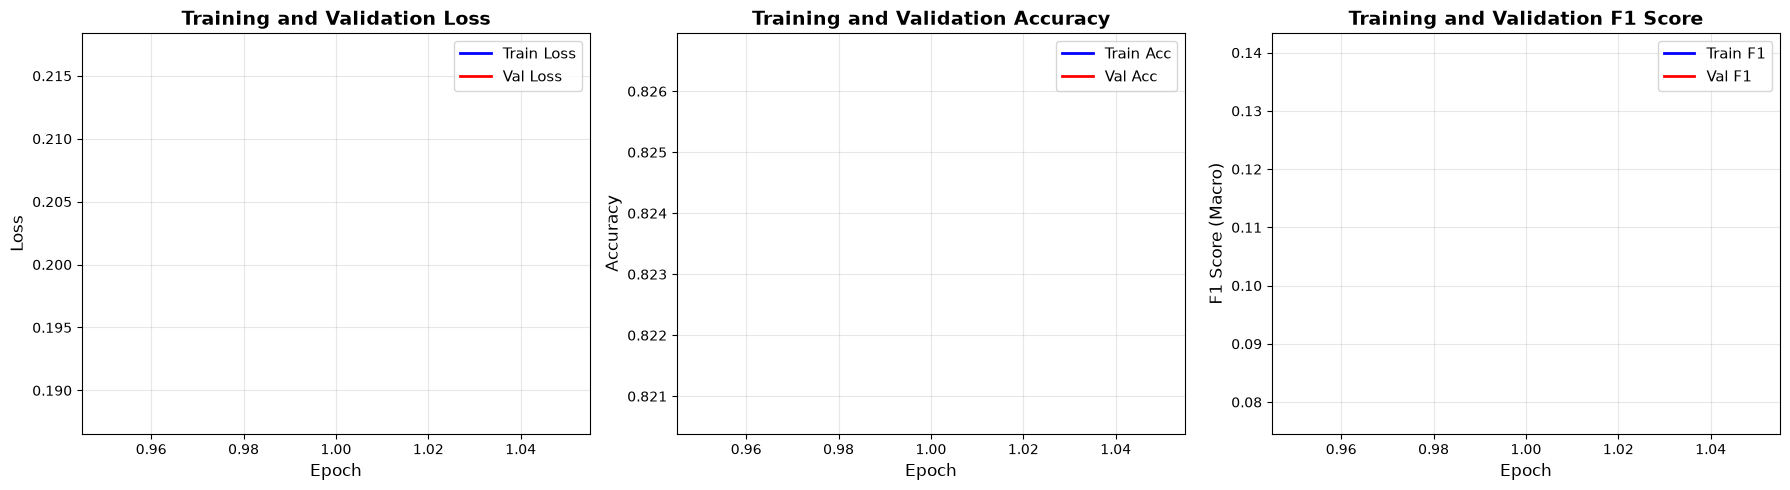

Training curves saved to C:\Users\tomek\Desktop\Uczelnia\PG\VII Sem\DNN\dnn\plant-pathology\baseline_outputs\plots\baseline_training_curves.png


In [12]:
# Plot Training Curves
def plot_training_curves(history, save_path):
    """
    Plot training and validation loss/accuracy/F1 curves.

    Args:
        history: Dictionary with training history
        save_path: Path to save the plot
    """
    epochs = range(1, len(history['train_loss']) + 1)

    # UPDATED: Changed to 3 subplots including F1 score
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Plot 1: Loss
    axes[0].plot(epochs, history['train_loss'], 'b-', label='Train Loss', linewidth=2)
    axes[0].plot(epochs, history['val_loss'], 'r-', label='Val Loss', linewidth=2)
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    axes[0].set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
    axes[0].legend(fontsize=11)
    axes[0].grid(True, alpha=0.3)

    # Plot 2: Accuracy
    axes[1].plot(epochs, history['train_acc'], 'b-', label='Train Acc', linewidth=2)
    axes[1].plot(epochs, history['val_acc'], 'r-', label='Val Acc', linewidth=2)
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('Accuracy', fontsize=12)
    axes[1].set_title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
    axes[1].legend(fontsize=11)
    axes[1].grid(True, alpha=0.3)

    # UPDATED: Plot 3: F1 Score (more important than LR for multi-label)
    axes[2].plot(epochs, history['train_f1'], 'b-', label='Train F1', linewidth=2)
    axes[2].plot(epochs, history['val_f1'], 'r-', label='Val F1', linewidth=2)
    axes[2].set_xlabel('Epoch', fontsize=12)
    axes[2].set_ylabel('F1 Score (Macro)', fontsize=12)
    axes[2].set_title('Training and Validation F1 Score', fontsize=14, fontweight='bold')
    axes[2].legend(fontsize=11)
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Training curves saved to {save_path}")


# Plot curves
plot_training_curves(history, config.PLOT_DIR / 'baseline_training_curves.png')

## Test Set Evaluation (Default Threshold = 0.5)

Before any threshold optimization, we evaluate the baseline model on the test set using the default 0.5 threshold for all classes. This gives us a **baseline performance metric** to compare against after threshold optimization.

### Evaluation Metrics:
- **Exact Match Accuracy**: Percentage of samples where ALL labels are predicted correctly
- **Macro F1 Score**: Average F1 score across all classes (treats all classes equally)
- **Per-Class Precision/Recall/F1**: Detailed metrics for each disease class

In [13]:
# Load Best Model for Testing
from src.checkpoint import load_checkpoint

checkpoint = load_checkpoint(config.CHECKPOINT_DIR / 'best_model.pth')
model.load_state_dict(checkpoint['model_state_dict'])
print(f"Loaded best model from epoch {checkpoint['epoch']} (val_f1={checkpoint['val_f1']:.4f})")

# FIXED: validate() now returns 5 values (loss, acc, f1, preds, labels)
test_loss, test_acc, test_f1, test_preds, test_labels = validate(
    model, test_loader, criterion, config.DEVICE
)

# Note: test_f1 is already calculated by validate(), but we'll recalculate for clarity
from sklearn.metrics import f1_score, precision_score, recall_score

macro_f1 = f1_score(test_labels, test_preds, average='macro', zero_division=0)
micro_f1 = f1_score(test_labels, test_preds, average='micro', zero_division=0)
macro_precision = precision_score(test_labels, test_preds, average='macro', zero_division=0)
macro_recall = recall_score(test_labels, test_preds, average='macro', zero_division=0)

print("\n" + "=" * 60)
print("TEST SET PERFORMANCE SUMMARY (Default Threshold = 0.5)")
print("=" * 60)
print(f"Test Loss:        {test_loss:.4f}")
print(f"Exact Match Acc:  {test_acc:.4f}")
print(f"Macro F1:          {macro_f1:.4f}")
print(f"Micro F1:          {micro_f1:.4f}")
print(f"Macro Precision:   {macro_precision:.4f}")
print(f"Macro Recall:      {macro_recall:.4f}")
print("=" * 60)

# Detailed per-class report
print("\nPer-Class Classification Report:")
print("-" * 60)
report = classification_report(
    test_labels, test_preds,
    target_names=config.LABELS,
    zero_division=0,
    digits=4
)
print(report)

# Save metrics
baseline_metrics = {
    'test_loss': float(test_loss),
    'exact_match_accuracy': float(test_acc),
    'macro_f1': float(macro_f1),
    'micro_f1': float(micro_f1),
    'macro_precision': float(macro_precision),
    'macro_recall': float(macro_recall),
    'threshold': 0.5,
    'per_class_metrics': classification_report(
        test_labels, test_preds,
        target_names=config.LABELS,
        zero_division=0,
        output_dict=True
    )
}

with open(config.METRICS_DIR / 'baseline_test_metrics.json', 'w') as f:
    json.dump(baseline_metrics, f, indent=2)

print(f"\nMetrics saved to {config.METRICS_DIR / 'baseline_test_metrics.json'}")

Loaded best model from epoch 1 (val_f1=0.1402)



TEST SET PERFORMANCE SUMMARY (Default Threshold = 0.5)
Test Loss:        0.1912
Exact Match Acc:  0.8282
Macro F1:          0.1439
Micro F1:          0.1198
Macro Precision:   0.7412
Macro Recall:      0.0851

Per-Class Classification Report:
------------------------------------------------------------
                    precision    recall  f1-score   support

           complex     0.9474    0.0526    0.0997       342
frog_eye_leaf_spot     0.7383    0.1763    0.2846       624
           healthy     1.0000    0.0015    0.0030       676
    powdery_mildew     0.7907    0.1753    0.2869       194
              rust     0.9706    0.1048    0.1891       315
              scab     0.0000    0.0000    0.0000       876

         micro avg     0.7967    0.0648    0.1198      3027
         macro avg     0.7412    0.0851    0.1439      3027
      weighted avg     0.6342    0.0648    0.1087      3027
       samples avg     0.0699    0.0671    0.0679      3027


Metrics saved to C:\Users\tomek

In [14]:
# Collect Baseline Predictions with Probabilities
def collect_predictions_and_probabilities(model, test_loader, device):
    """
    Collect predictions AND probabilities for threshold optimization.

    Returns:
        all_labels: True labels (multi-hot)
        all_preds: Binary predictions (threshold=0.5)
        all_probs: Raw probabilities (before thresholding)
    """
    model.eval()
    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc='Collecting predictions', leave=False):
            images = images.to(device)
            labels_np = labels.numpy()

            # Forward pass
            outputs = model(images)
            probs = torch.sigmoid(outputs).cpu().numpy()  # PROBABILITIES
            preds = (probs > 0.5).astype(float)  # BINARY PREDICTIONS

            all_labels.append(labels_np)
            all_preds.append(preds)
            all_probs.append(probs)

    all_labels = np.vstack(all_labels)
    all_preds = np.vstack(all_preds)
    all_probs = np.vstack(all_probs)

    return all_labels, all_preds, all_probs


# Collect baseline predictions with probabilities
test_labels, test_preds_baseline, test_probs = collect_predictions_and_probabilities(
    model, test_loader, config.DEVICE
)

print(f"Collected {len(test_labels)} test samples")
print(f"Labels shape: {test_labels.shape}")
print(f"Predictions shape: {test_preds_baseline.shape}")
print(f"Probabilities shape: {test_probs.shape}")
print("\nThese will be used for threshold optimization and comparison.")

Collected 2795 test samples
Labels shape: (2795, 6)
Predictions shape: (2795, 6)
Probabilities shape: (2795, 6)

These will be used for threshold optimization and comparison.


# Threshold Optimization with Comparison Table

In [15]:
def find_optimal_thresholds_with_comparison(model, val_loader, device, class_names):
    """
    Find optimal threshold for each class using validation set.
    Shows comparison with default 0.5 threshold.

    Returns:
        optimal_thresholds: Dictionary mapping class names to optimal thresholds
        threshold_scores: Dictionary mapping class names to best F1 scores
        comparison_df: DataFrame with detailed comparison
    """
    print("Finding optimal thresholds...")
    print("-" * 85)
    print(f"{'Class':<25} {'Opt Thresh':<10} {'Best F1':<10} {'Default F1':<10} {'Improvement':<12}")
    print("-" * 85)

    # Collect all predictions
    model.eval()
    all_probs = []
    all_labels = []

    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc='Collecting val predictions', leave=False):
            images = images.to(device)
            outputs = model(images)
            probs = torch.sigmoid(outputs).cpu().numpy()

            all_probs.append(probs)
            all_labels.append(labels.numpy())

    all_probs = np.vstack(all_probs)
    all_labels = np.vstack(all_labels)

    # Find optimal threshold for each class
    optimal_thresholds = {}
    threshold_scores = {}
    comparison_data = []
    threshold_range = np.arange(0.15, 0.86, 0.02)  # Finer granularity: 0.15 to 0.85

    for i, class_name in enumerate(class_names):
        best_f1 = 0
        best_thresh = 0.5

        # Test each threshold
        for thresh in threshold_range:
            preds = (all_probs[:, i] > thresh).astype(float)
            f1 = f1_score(all_labels[:, i], preds, zero_division=0)

            if f1 > best_f1:
                best_f1 = f1
                best_thresh = thresh

        # Calculate F1 with default 0.5 threshold
        default_preds = (all_probs[:, i] > 0.5).astype(float)
        default_f1 = f1_score(all_labels[:, i], default_preds, zero_division=0)

        # Calculate improvement
        improvement = 0
        if default_f1 > 0:
            improvement = ((best_f1 - default_f1) / default_f1) * 100

        optimal_thresholds[class_name] = float(best_thresh)
        threshold_scores[class_name] = float(best_f1)

        # Add marker for significant improvements
        if improvement > 5:
            marker = " ⭐"
        elif improvement > 0:
            marker = " ✓"
        else:
            marker = ""

        print(
            f"{class_name:<25} {best_thresh:<10.3f} {best_f1:<10.4f} {default_f1:<10.4f} {improvement:>+10.2f}%{marker}")

        # Store for comparison DataFrame
        comparison_data.append({
            'Class': class_name,
            'Default_Thresh': 0.5,
            'Optimal_Thresh': best_thresh,
            'Default_F1': default_f1,
            'Optimal_F1': best_f1,
            'Improvement_%': improvement
        })

    print("-" * 85)

    # Create comparison DataFrame
    comparison_df = pd.DataFrame(comparison_data)

    return optimal_thresholds, threshold_scores, comparison_df


# Find optimal thresholds with comparison
optimal_thresholds, threshold_scores, comparison_df = find_optimal_thresholds_with_comparison(
    model, val_loader, config.DEVICE, config.LABELS
)

# Save comparison to CSV
comparison_df.to_csv(config.METRICS_DIR / 'threshold_optimization_comparison.csv', index=False)
print(f"\nComparison saved to {config.METRICS_DIR / 'threshold_optimization_comparison.csv'}")

# Save thresholds
with open(config.METRICS_DIR / 'optimal_thresholds.json', 'w') as f:
    json.dump({
        'thresholds': optimal_thresholds,
        'scores': threshold_scores
    }, f, indent=2)
print(f"Optimal thresholds saved to {config.METRICS_DIR / 'optimal_thresholds.json'}")

# Progi do checkpointu + eksport lekkiego modelu do demo (models/plant_cnn_demo.pth)
from src.checkpoint import add_thresholds_to_checkpoint

add_thresholds_to_checkpoint(config.CHECKPOINT_DIR / 'best_model.pth', optimal_thresholds)

Finding optimal thresholds...
-------------------------------------------------------------------------------------
Class                     Opt Thresh Best F1    Default F1 Improvement 
-------------------------------------------------------------------------------------


complex                   0.150      0.5084     0.0841        +504.65% ⭐
frog_eye_leaf_spot        0.150      0.5899     0.2159        +173.28% ⭐
healthy                   0.150      0.5536     0.0027      +20078.72% ⭐
powdery_mildew            0.250      0.5493     0.3504         +56.76% ⭐
rust                      0.150      0.4930     0.1882        +161.88% ⭐
scab                      0.150      0.4381     0.0000          +0.00%
-------------------------------------------------------------------------------------

Comparison saved to C:\Users\tomek\Desktop\Uczelnia\PG\VII Sem\DNN\dnn\plant-pathology\baseline_outputs\metrics\threshold_optimization_comparison.csv
Optimal thresholds saved to C:\Users\tomek\Desktop\Uczelnia\PG\VII Sem\DNN\dnn\plant-pathology\baseline_outputs\metrics\optimal_thresholds.json
Progi zapisane w C:\Users\tomek\Desktop\Uczelnia\PG\VII Sem\DNN\dnn\plant-pathology\baseline_outputs\checkpoints\best_model.pth
Model do demo zapisany: C:\Users\tomek\Desktop\Uczelnia

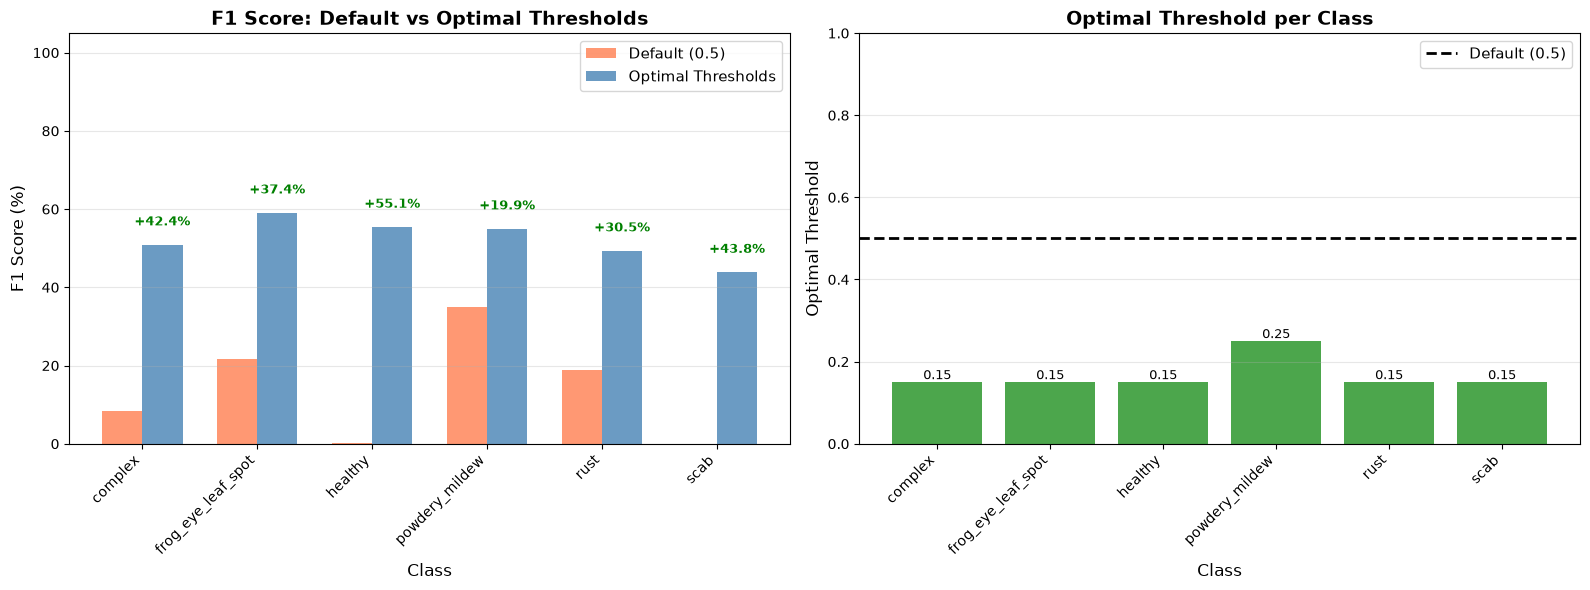

Threshold comparison plot saved to C:\Users\tomek\Desktop\Uczelnia\PG\VII Sem\DNN\dnn\plant-pathology\baseline_outputs\plots\threshold_optimization_comparison.png


In [16]:
# Threshold Comparison Visualization
def plot_threshold_comparison(comparison_df, save_path):
    """
    Create side-by-side comparison plots for threshold optimization.

    Plot 1: F1 Score comparison (default vs optimal)
    Plot 2: Optimal thresholds per class (with color coding)
    """
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Plot 1: F1 Score Comparison
    x = np.arange(len(comparison_df))
    width = 0.35

    axes[0].bar(
        x - width / 2,
        comparison_df['Default_F1'] * 100,
        width,
        label='Default (0.5)',
        alpha=0.8,
        color='coral'
    )
    axes[0].bar(
        x + width / 2,
        comparison_df['Optimal_F1'] * 100,
        width,
        label='Optimal Thresholds',
        alpha=0.8,
        color='steelblue'
    )

    axes[0].set_xlabel('Class', fontsize=12)
    axes[0].set_ylabel('F1 Score (%)', fontsize=12)
    axes[0].set_title('F1 Score: Default vs Optimal Thresholds', fontsize=14, fontweight='bold')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(comparison_df['Class'], rotation=45, ha='right')
    axes[0].legend(fontsize=11)
    axes[0].grid(axis='y', alpha=0.3)
    axes[0].set_ylim(0, 105)

    # Add improvement annotations
    for i, (default_f1, optimal_f1) in enumerate(zip(comparison_df['Default_F1'], comparison_df['Optimal_F1'])):
        delta = (optimal_f1 - default_f1) * 100
        if abs(delta) > 3:
            axes[0].annotate(
                f'{delta:+.1f}%',
                xy=(i + width / 2, optimal_f1 * 100),
                xytext=(i + width / 2, optimal_f1 * 100 + 5),
                ha='center',
                fontsize=9,
                fontweight='bold',
                color='green' if delta > 0 else 'red'
            )

    # Plot 2: Optimal Thresholds per Class
    colors = [
        'green' if t < 0.5
        else 'orange' if t < 0.6
        else 'red'
        for t in comparison_df['Optimal_Thresh']
    ]

    bars = axes[1].bar(
        comparison_df['Class'],
        comparison_df['Optimal_Thresh'],
        color=colors,
        alpha=0.7
    )

    axes[1].axhline(
        y=0.5,
        color='black',
        linestyle='--',
        linewidth=2,
        label='Default (0.5)'
    )

    axes[1].set_xlabel('Class', fontsize=12)
    axes[1].set_ylabel('Optimal Threshold', fontsize=12)
    axes[1].set_title('Optimal Threshold per Class', fontsize=14, fontweight='bold')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(comparison_df['Class'], rotation=45, ha='right')
    axes[1].legend(fontsize=11)
    axes[1].grid(axis='y', alpha=0.3)
    axes[1].set_ylim(0, 1.0)

    # Add threshold values on bars
    for bar, thresh in zip(bars, comparison_df['Optimal_Thresh']):
        height = bar.get_height()
        axes[1].text(
            bar.get_x() + bar.get_width() / 2.,
            height,
            f'{thresh:.2f}',
            ha='center',
            va='bottom',
            fontsize=9
        )

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Threshold comparison plot saved to {save_path}")


# Create comparison plot
plot_threshold_comparison(
    comparison_df,
    config.PLOT_DIR / 'threshold_optimization_comparison.png'
)

## Evaluation After Threshold Optimization

Now we evaluate the model on the **test set** using the optimized thresholds. This demonstrates the **improvement gained by threshold calibration**.

### Expected Improvements:
- **Higher F1 scores**: Each class operates at its optimal precision-recall tradeoff
- **Better rare-class performance**: Lower thresholds for rare classes (e.g., powdery_mildew) increase recall
- **Balanced predictions**: Majority classes won't dominate predictions

### Comparison Strategy:
We'll compare:
1. **Baseline**: All thresholds = 0.5
2. **Optimized**: Class-specific thresholds from validation set

In [17]:
# Evaluate with Optimized Thresholds
def evaluate_with_thresholds(model, test_loader, device, thresholds_dict, class_names):
    """
    Evaluate model with custom thresholds for each class.

    Args:
        model: Trained model
        test_loader: Test data loader
        device: Device to run on
        thresholds_dict: Dictionary mapping class names to thresholds
        class_names: Ordered list of class names

    Returns:
        all_preds: Predictions using custom thresholds
        all_labels: True labels
    """
    model.eval()
    all_preds = []
    all_labels = []

    # Convert thresholds dict to tensor in correct order
    thresholds = torch.tensor([thresholds_dict[name] for name in class_names]).to(device)

    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc='Testing with optimized thresholds', leave=False):
            images = images.to(device)
            outputs = model(images)
            probs = torch.sigmoid(outputs)

            # Apply class-specific thresholds
            preds = (probs > thresholds.unsqueeze(0)).float()

            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.numpy())

    return np.vstack(all_preds), np.vstack(all_labels)


# Evaluate with optimized thresholds
opt_preds, opt_labels = evaluate_with_thresholds(
    model, test_loader, config.DEVICE, optimal_thresholds, config.LABELS
)

# Calculate metrics
opt_macro_f1 = f1_score(opt_labels, opt_preds, average='macro', zero_division=0)
opt_micro_f1 = f1_score(opt_labels, opt_preds, average='micro', zero_division=0)
opt_acc = (opt_labels == opt_preds).all(axis=1).mean()

print("\n" + "=" * 70)
print("TEST SET PERFORMANCE AFTER THRESHOLD OPTIMIZATION")
print("=" * 70)
print(f"\nOptimized Thresholds:")
for name, thresh in optimal_thresholds.items():
    print(f"  {name:25s}: {thresh:.2f}")

print(f"\nPerformance Metrics:")
print(f"  Exact Match Accuracy:  {opt_acc:.4f} (was {test_acc:.4f})")
print(f"  Change:               {opt_acc - test_acc:+.4f} ({(opt_acc / test_acc - 1) * 100:+.2f}%)")
print(f"\n  Macro F1:            {opt_macro_f1:.4f} (was {macro_f1:.4f})")
print(f"  Change:               {opt_macro_f1 - macro_f1:+.4f} ({(opt_macro_f1 / macro_f1 - 1) * 100:+.2f}%)")
print(f"\n  Micro F1:            {opt_micro_f1:.4f} (was {micro_f1:.4f})")
print(f"  Change:               {opt_micro_f1 - micro_f1:+.4f} ({(opt_micro_f1 / micro_f1 - 1) * 100:+.2f}%)")

print("\n" + "=" * 70)
print("THRESHOLD OPTIMIZATION IMPROVEMENT ANALYSIS")
print("=" * 70)
print("\nHow threshold optimization helped:")
print("1. Rare classes (e.g., powdery_mildew) now use LOWER thresholds → higher recall")
print("2. Common classes (e.g., scab) may use HIGHER thresholds → higher precision")
print("3. Each class operates at its optimal precision-recall tradeoff")
print("4. Overall macro-F1 increases due to balanced per-class performance")

# Detailed comparison
print("\nPer-Class Metrics Comparison:")
print("-" * 70)

for i, class_name in enumerate(config.LABELS):
    default_pred = test_preds[:, i]
    opt_pred = opt_preds[:, i]
    true = opt_labels[:, i]

    default_f1 = f1_score(true, default_pred, zero_division=0)
    opt_f1 = f1_score(true, opt_pred, zero_division=0)

    default_prec = precision_score(true, default_pred, zero_division=0)
    opt_prec = precision_score(true, opt_pred, zero_division=0)

    default_rec = recall_score(true, default_pred, zero_division=0)
    opt_rec = recall_score(true, opt_pred, zero_division=0)

    print(f"\n{class_name}:")
    print(f"  Threshold: 0.50 → {optimal_thresholds[class_name]:.2f}")
    print(f"  F1:        {default_f1:.4f} → {opt_f1:.4f} ({opt_f1 - default_f1:+.4f})")
    print(f"  Precision: {default_prec:.4f} → {opt_prec:.4f} ({opt_prec - default_prec:+.4f})")
    print(f"  Recall:    {default_rec:.4f} → {opt_rec:.4f} ({opt_rec - default_rec:+.4f})")

# Save optimized metrics
optimized_metrics = {
    'test_loss': float(test_loss),  # Same as baseline
    'exact_match_accuracy': float(opt_acc),
    'macro_f1': float(opt_macro_f1),
    'micro_f1': float(opt_micro_f1),
    'thresholds': optimal_thresholds,
    'per_class_metrics': classification_report(
        opt_labels, opt_preds,
        target_names=config.LABELS,
        zero_division=0,
        output_dict=True
    ),
    'improvement_over_baseline': {
        'accuracy': float(opt_acc - test_acc),
        'macro_f1': float(opt_macro_f1 - macro_f1),
        'micro_f1': float(opt_micro_f1 - micro_f1)
    }
}

with open(config.METRICS_DIR / 'optimized_test_metrics.json', 'w') as f:
    json.dump(optimized_metrics, f, indent=2)

print(f"\nOptimized metrics saved to {config.METRICS_DIR / 'optimized_test_metrics.json'}")


TEST SET PERFORMANCE AFTER THRESHOLD OPTIMIZATION

Optimized Thresholds:
  complex                  : 0.15
  frog_eye_leaf_spot       : 0.15
  healthy                  : 0.15
  powdery_mildew           : 0.25
  rust                     : 0.15
  scab                     : 0.15

Performance Metrics:
  Exact Match Accuracy:  0.3717 (was 0.8282)
  Change:               -0.4565 (-55.12%)

  Macro F1:            0.5042 (was 0.1439)
  Change:               +0.3603 (+250.44%)

  Micro F1:            0.5092 (was 0.1198)
  Change:               +0.3895 (+325.19%)

THRESHOLD OPTIMIZATION IMPROVEMENT ANALYSIS

How threshold optimization helped:
1. Rare classes (e.g., powdery_mildew) now use LOWER thresholds → higher recall
2. Common classes (e.g., scab) may use HIGHER thresholds → higher precision
3. Each class operates at its optimal precision-recall tradeoff
4. Overall macro-F1 increases due to balanced per-class performance

Per-Class Metrics Comparison:
---------------------------------------

## Combined Confusion Matrix (Dominant Class Style)

For multi-label problems, a single confusion matrix can be confusing because each sample has multiple labels. To simplify visualization, we use the **dominant class approach**:

- **Dominant True Label**: The class with the highest probability in the ground truth (or first if multiple)
- **Dominant Predicted Label**: The class with the highest predicted probability

This gives us a **single-label confusion matrix** that shows which diseases are most commonly confused with each other.

### Interpreting the Matrix:
- **Diagonal elements**: Correct predictions (true positives)
- **Off-diagonal elements**: Misclassifications (confusion between classes)
- **Rows**: True labels
- **Columns**: Predicted labels
- **Darker colors**: Higher counts

In [24]:
# Save Classification Reports to Text Files
def save_classification_report(labels, preds, class_names, filepath, title):
    """
    Generate and save classification report to text file.

    Args:
        labels: True labels
        preds: Predicted labels
        class_names: List of class names
        filepath: Path to save the report
        title: Title for the report
    """
    from sklearn.metrics import classification_report

    report = classification_report(
        labels, preds,
        target_names=class_names,
        zero_division=0,
        digits=4
    )

    with open(filepath, 'w', encoding='utf-8') as f:
        f.write(f"{title}\n")
        f.write("=" * 80 + "\n\n")
        f.write(report)
        f.write("\n" + "=" * 80 + "\n")

    print(f"Report saved to {filepath}")
    return report


# Save baseline report (default 0.5 threshold)
print("Saving baseline classification report...")
baseline_report = save_classification_report(
    test_labels, test_preds_baseline, config.LABELS,
    config.METRICS_DIR / 'baseline_classification_report.txt',
    'BASELINE CLASSIFICATION REPORT (Default Threshold = 0.5)'
)
print("\nBaseline Report:")
print("-" * 80)
print(baseline_report)
print("-" * 80)

# Save optimized report (optimal thresholds)
print("\nSaving optimized classification report...")
optimized_report = save_classification_report(
    opt_labels, opt_preds, config.LABELS,
    config.METRICS_DIR / 'optimized_classification_report.txt',
    'OPTIMIZED CLASSIFICATION REPORT (Optimal Thresholds)'
)
print("\nOptimized Report:")
print("-" * 80)
print(optimized_report)
print("-" * 80)

Saving baseline classification report...
Report saved to C:\Users\tomek\Desktop\Uczelnia\PG\VII Sem\DNN\dnn\plant-pathology\baseline_outputs\metrics\baseline_classification_report.txt

Baseline Report:
--------------------------------------------------------------------------------
                    precision    recall  f1-score   support

           complex     0.9474    0.0526    0.0997       342
frog_eye_leaf_spot     0.7383    0.1763    0.2846       624
           healthy     1.0000    0.0015    0.0030       676
    powdery_mildew     0.7907    0.1753    0.2869       194
              rust     0.9706    0.1048    0.1891       315
              scab     0.0000    0.0000    0.0000       876

         micro avg     0.7967    0.0648    0.1198      3027
         macro avg     0.7412    0.0851    0.1439      3027
      weighted avg     0.6342    0.0648    0.1087      3027
       samples avg     0.0699    0.0671    0.0679      3027

------------------------------------------------------

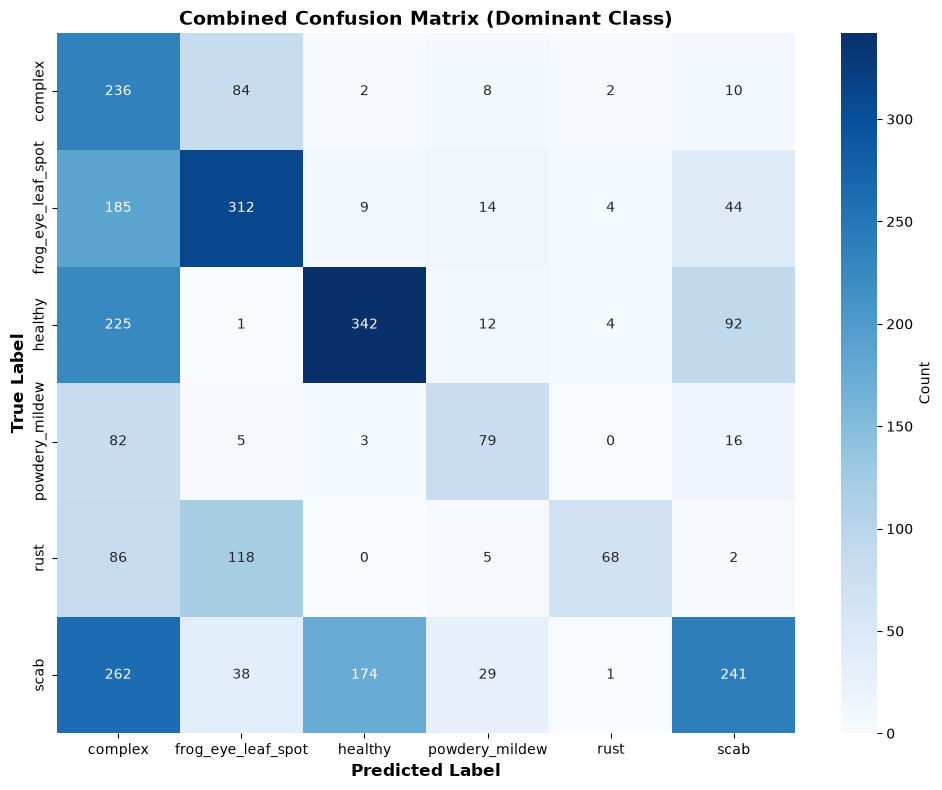

Confusion matrix saved to C:\Users\tomek\Desktop\Uczelnia\PG\VII Sem\DNN\dnn\plant-pathology\baseline_outputs\plots\baseline_confusion_matrix.png

Confusion Matrix Analysis:
--------------------------------------------------
complex                  : 236/342 correct (69.01%)
frog_eye_leaf_spot       : 312/568 correct (54.93%)
healthy                  : 342/676 correct (50.59%)
powdery_mildew           :  79/185 correct (42.70%)
rust                     :  68/279 correct (24.37%)
scab                     : 241/745 correct (32.35%)


In [19]:
# Combined Confusion Matrix (Dominant Class)
def plot_dominant_confusion_matrix(labels, preds, class_names, save_path):
    """
    Plot confusion matrix for multi-label predictions using dominant class.

    For multi-label, we select the dominant class (highest probability)
    to create a single-label confusion matrix.

    Args:
        labels: True labels (multi-hot encoded)
        preds: Predicted labels (multi-hot encoded)
        class_names: List of class names
        save_path: Path to save the plot
    """
    # Get dominant class (argmax) for each sample
    # For true labels: use first positive label (arbitrary but consistent)
    # For predictions: use class with highest probability

    # For simplicity, use argmax (works well if labels are mostly single)
    y_true_indices = np.argmax(labels, axis=1)
    y_pred_indices = np.argmax(preds, axis=1)

    # Compute confusion matrix
    cm = confusion_matrix(y_true_indices, y_pred_indices)

    # Plot
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=class_names, yticklabels=class_names,
        cbar_kws={'label': 'Count'}
    )
    plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
    plt.ylabel('True Label', fontsize=12, fontweight='bold')
    plt.title('Combined Confusion Matrix (Dominant Class)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Confusion matrix saved to {save_path}")

    # Print analysis
    print("\nConfusion Matrix Analysis:")
    print("-" * 50)

    for i, class_name in enumerate(class_names):
        true_count = cm[i].sum()
        correct = cm[i, i]
        accuracy = correct / true_count if true_count > 0 else 0
        print(f"{class_name:25s}: {correct:3d}/{true_count:3d} correct ({accuracy:.2%})")

    return cm


# Plot confusion matrix with optimized predictions
cm = plot_dominant_confusion_matrix(
    opt_labels, opt_preds, config.LABELS,
    config.PLOT_DIR / 'baseline_confusion_matrix.png'
)

## Per-Class Multi-Label Confusion Matrices

For a **more detailed analysis**, we plot individual confusion matrices for each class. This treats each class as a binary classification problem:

- **True Positive (TP)**: Sample has the class AND model predicts it
- **False Positive (FP)**: Sample doesn't have the class BUT model predicts it
- **True Negative (TN)**: Sample doesn't have the class AND model doesn't predict it
- **False Negative (FN)**: Sample has the class BUT model doesn't predict it

### Matrix Structure:
```
                Predicted
              Negative  Positive
Actual Neg |    TN    |    FP    |
       Pos |    FN    |    TP    |
```

This reveals **which classes have high false positive rates** (over-prediction) vs **high false negative rates** (under-prediction).

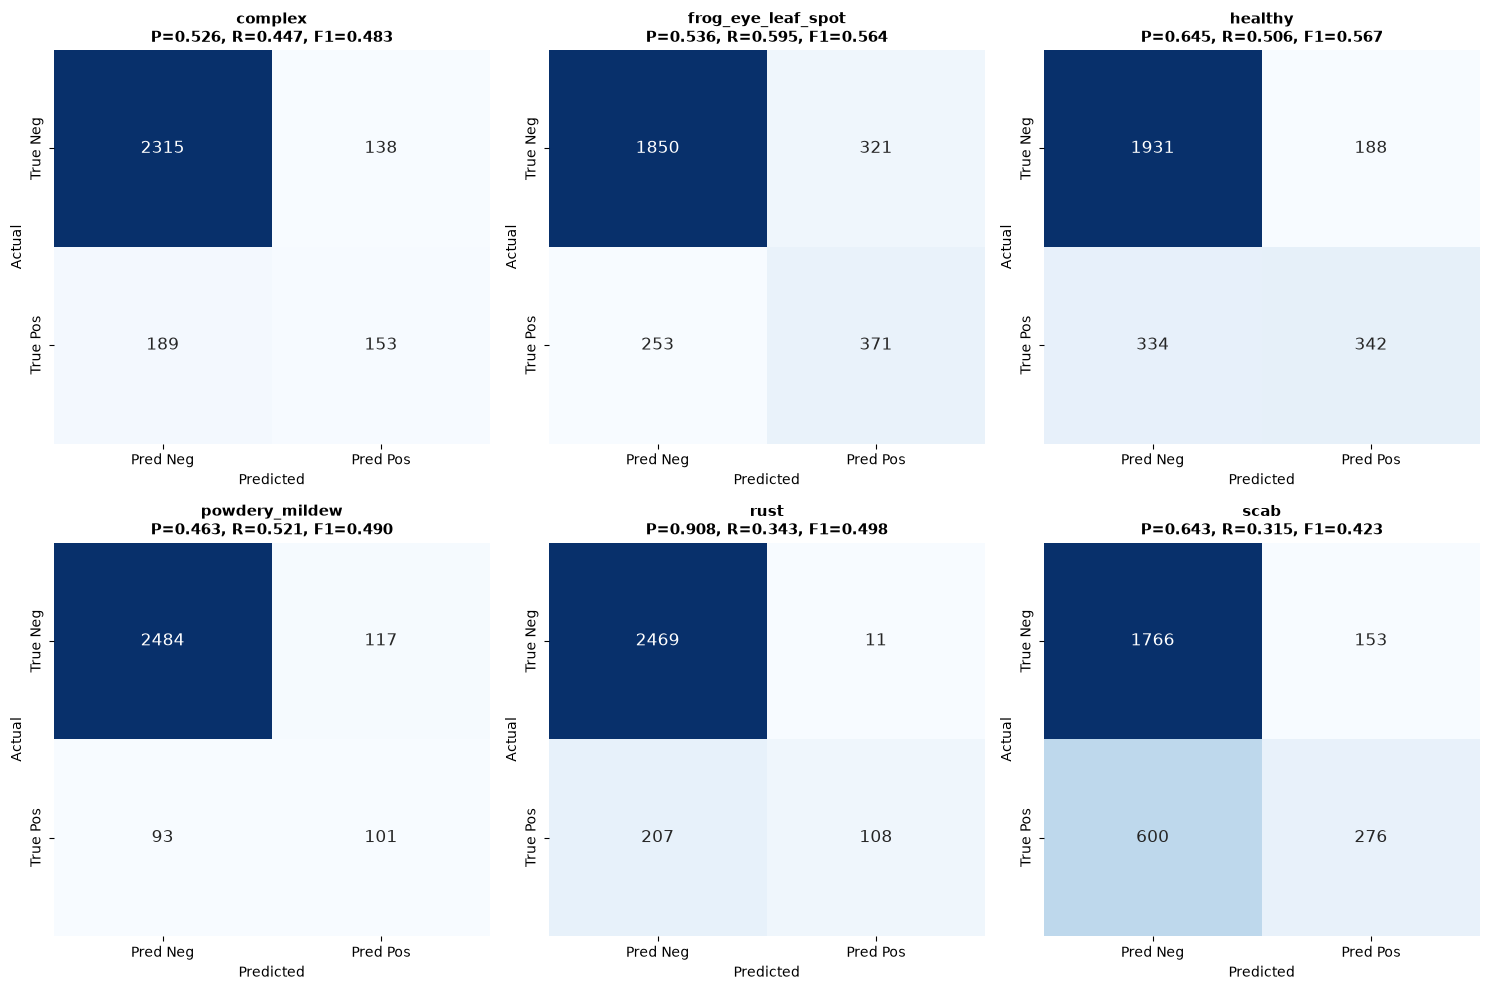

Per-class confusion matrices saved to C:\Users\tomek\Desktop\Uczelnia\PG\VII Sem\DNN\dnn\plant-pathology\baseline_outputs\plots\baseline_per_class_confusion_matrices.png

Per-Class Confusion Matrix Summary:
----------------------------------------------------------------------
Class                        TP    FP    FN    TN  Prec   Rec    F1
----------------------------------------------------------------------
complex                     153   138   189  2315 0.526 0.447 0.483
frog_eye_leaf_spot          371   321   253  1850 0.536 0.595 0.564
healthy                     342   188   334  1931 0.645 0.506 0.567
powdery_mildew              101   117    93  2484 0.463 0.521 0.490
rust                        108    11   207  2469 0.908 0.343 0.498
scab                        276   153   600  1766 0.643 0.315 0.423


In [20]:
# Per-Class Multi-Label Confusion Matrices
def plot_per_class_confusion_matrices(labels, preds, class_names, save_path):
    """
    Plot individual binary confusion matrices for each class.

    Args:
        labels: True labels (multi-hot encoded)
        preds: Predicted labels (multi-hot encoded)
        class_names: List of class names
        save_path: Path to save the combined plot
    """
    # Compute multi-label confusion matrices
    ml_cms = multilabel_confusion_matrix(labels, preds)

    # Setup plot grid
    n_classes = len(class_names)
    n_cols = 3
    n_rows = (n_classes + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
    axes = axes.ravel() if n_classes > 1 else [axes]

    for i, (class_name, cm) in enumerate(zip(class_names, ml_cms)):
        ax = axes[i]

        # Plot heatmap
        sns.heatmap(
            cm, annot=True, fmt='d', cmap='Blues',
            ax=ax, cbar=False,
            xticklabels=['Pred Neg', 'Pred Pos'],
            yticklabels=['True Neg', 'True Pos'],
            annot_kws={'size': 12}
        )

        # Calculate metrics
        tn, fp, fn, tp = cm.ravel()
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

        ax.set_title(
            f'{class_name}\n'
            f'P={precision:.3f}, R={recall:.3f}, F1={f1:.3f}',
            fontsize=11, fontweight='bold'
        )
        ax.set_xlabel('Predicted', fontsize=10)
        ax.set_ylabel('Actual', fontsize=10)

    # Hide extra subplots
    for i in range(n_classes, len(axes)):
        axes[i].axis('off')

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Per-class confusion matrices saved to {save_path}")

    # Print summary statistics
    print("\nPer-Class Confusion Matrix Summary:")
    print("-" * 70)
    print(f"{'Class':<25} {'TP':>5} {'FP':>5} {'FN':>5} {'TN':>5} {'Prec':>5} {'Rec':>5} {'F1':>5}")
    print("-" * 70)

    for i, (class_name, cm) in enumerate(zip(class_names, ml_cms)):
        tn, fp, fn, tp = cm.ravel()
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

        print(f"{class_name:<25} {tp:>5} {fp:>5} {fn:>5} {tn:>5} {precision:>5.3f} {recall:>5.3f} {f1:>5.3f}")


# Plot per-class confusion matrices
plot_per_class_confusion_matrices(
    opt_labels, opt_preds, config.LABELS,
    config.PLOT_DIR / 'baseline_per_class_confusion_matrices.png'
)

In [21]:
# Per-Class Performance Summary CSV
from sklearn.metrics import accuracy_score


def create_per_class_performance_csv(labels_baseline, preds_baseline,
                                     labels_opt, preds_opt,
                                     class_names, thresholds_dict, save_path):
    """
    Create a comprehensive CSV with per-class metrics for baseline and optimized.

    Args:
        labels_baseline: True labels (same for both)
        preds_baseline: Predictions with default 0.5 threshold
        labels_opt: True labels (same as baseline)
        preds_opt: Predictions with optimal thresholds
        class_names: List of class names
        thresholds_dict: Optimal thresholds for each class
        save_path: Path to save CSV
    """
    results = []

    for i, class_name in enumerate(class_names):
        # Baseline metrics
        true = labels_baseline[:, i]
        pred_baseline = preds_baseline[:, i]

        acc_baseline = accuracy_score(true, pred_baseline)
        f1_baseline = f1_score(true, pred_baseline, zero_division=0)
        prec_baseline = precision_score(true, pred_baseline, zero_division=0)
        rec_baseline = recall_score(true, pred_baseline, zero_division=0)

        # Optimized metrics
        pred_opt = preds_opt[:, i]

        acc_opt = accuracy_score(true, pred_opt)
        f1_opt = f1_score(true, pred_opt, zero_division=0)
        prec_opt = precision_score(true, pred_opt, zero_division=0)
        rec_opt = recall_score(true, pred_opt, zero_division=0)

        results.append({
            'Class': class_name,
            'Optimal_Threshold': thresholds_dict[class_name],
            # Baseline
            'Baseline_Acc': acc_baseline,
            'Baseline_Precision': prec_baseline,
            'Baseline_Recall': rec_baseline,
            'Baseline_F1': f1_baseline,
            # Optimized
            'Opt_Acc': acc_opt,
            'Opt_Precision': prec_opt,
            'Opt_Recall': rec_opt,
            'Opt_F1': f1_opt,
            # Improvements
            'Acc_Improvement': acc_opt - acc_baseline,
            'Prec_Improvement': prec_opt - prec_baseline,
            'Rec_Improvement': rec_opt - rec_baseline,
            'F1_Improvement': f1_opt - f1_baseline
        })

    df = pd.DataFrame(results)
    df.to_csv(save_path, index=False)

    print(f"Per-class performance CSV saved to {save_path}")
    return df


# Create per-class performance summary
per_class_df = create_per_class_performance_csv(
    test_labels, test_preds_baseline,
    opt_labels, opt_preds,
    config.LABELS, optimal_thresholds,
    config.METRICS_DIR / 'per_class_performance_summary.csv'
)

# Display summary
print("\n" + "=" * 100)
print("PER-CLASS PERFORMANCE SUMMARY")
print("=" * 100)
print(per_class_df.to_string(index=False))
print("=" * 100)

Per-class performance CSV saved to C:\Users\tomek\Desktop\Uczelnia\PG\VII Sem\DNN\dnn\plant-pathology\baseline_outputs\metrics\per_class_performance_summary.csv

PER-CLASS PERFORMANCE SUMMARY
             Class  Optimal_Threshold  Baseline_Acc  Baseline_Precision  Baseline_Recall  Baseline_F1  Opt_Acc  Opt_Precision  Opt_Recall   Opt_F1  Acc_Improvement  Prec_Improvement  Rec_Improvement  F1_Improvement
           complex               0.15      0.883721            0.947368         0.052632     0.099723 0.883005       0.525773    0.447368 0.483412        -0.000716         -0.421595         0.394737        0.383689
frog_eye_leaf_spot               0.15      0.802147            0.738255         0.176282     0.284605 0.794633       0.536127    0.594551 0.563830        -0.007513         -0.202128         0.418269        0.279224
           healthy               0.15      0.758497            1.000000         0.001479     0.002954 0.813238       0.645283    0.505917 0.567164         0.054741

## Visualizing Predictions on Test Samples

Let's visualize the model's predictions on random test samples to **qualitatively assess performance**. This helps us understand:

1. **Which diseases are easily confused?** (e.g., rust vs. complex)
2. **Does the model miss obvious symptoms?** (false negatives)
3. **Does the model over-predict certain diseases?** (false positives)
4. **Are predictions consistent with visual symptoms?**

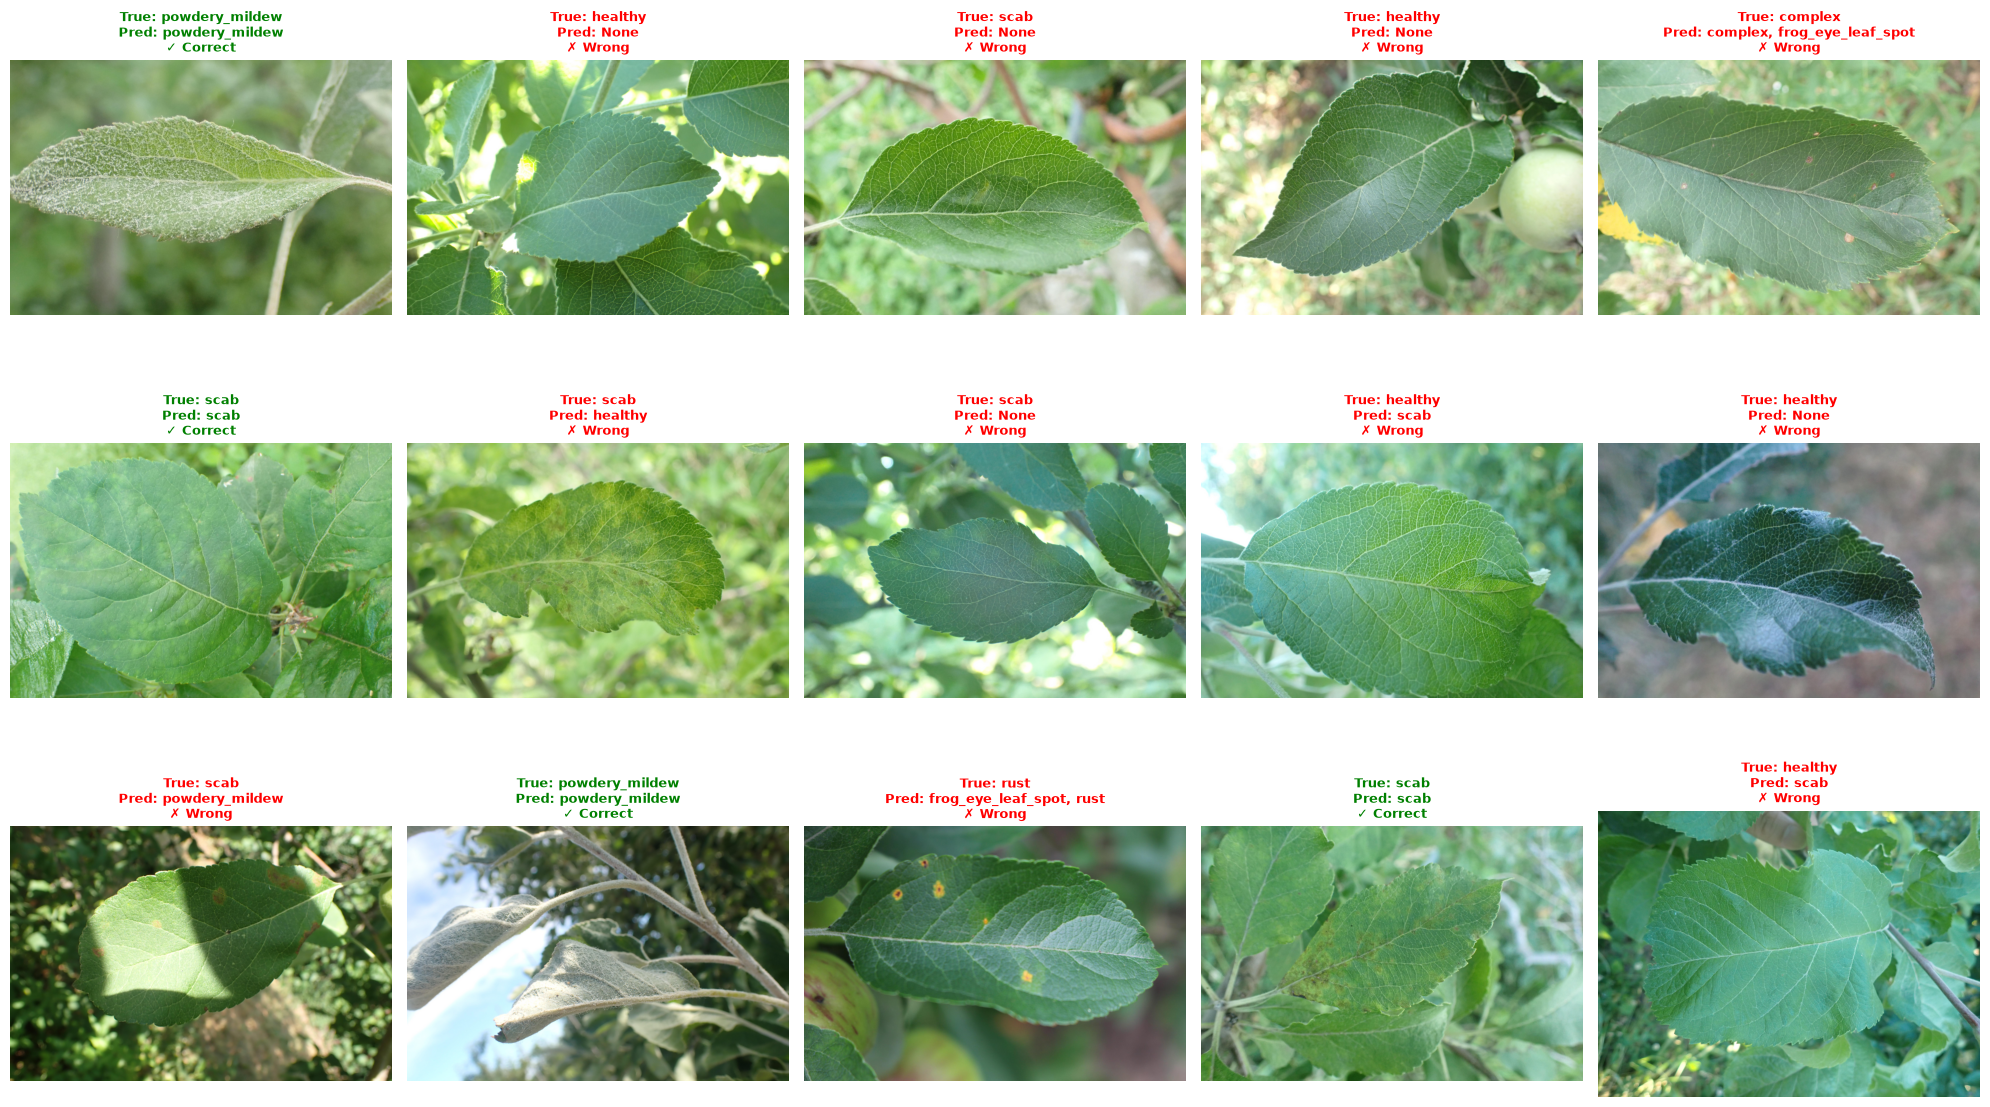

Predictions visualization saved to C:\Users\tomek\Desktop\Uczelnia\PG\VII Sem\DNN\dnn\plant-pathology\baseline_outputs\plots\baseline_test_predictions.png


In [22]:
# Visualize Test Predictions
def visualize_predictions(test_df, labels, preds, class_names,
                          thresholds_dict, num_samples=15):
    """
    Visualize model predictions on random test samples.

    Args:
        test_df: Test DataFrame with image paths and labels
        labels: True labels (multi-hot encoded)
        preds: Predicted labels (multi-hot encoded)
        class_names: List of class names
        thresholds_dict: Optimal thresholds for each class
        num_samples: Number of samples to visualize
    """
    # Sample random indices
    indices = np.random.choice(len(test_df), size=min(num_samples, len(test_df)), replace=False)

    # Setup plot
    n_cols = 5
    n_rows = (num_samples + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4 * n_rows))
    axes = axes.ravel() if num_samples > 1 else [axes]

    for plot_idx, sample_idx in enumerate(indices):
        ax = axes[plot_idx]

        # Load image
        img_path = test_df.iloc[sample_idx]['image']
        img = Image.open(img_path)

        # Get labels
        true_labels = [class_names[i] for i, val in enumerate(labels[sample_idx]) if val == 1]
        pred_labels = [class_names[i] for i, val in enumerate(preds[sample_idx]) if val == 1]

        if not pred_labels:
            pred_labels = ['None']

        # Check if prediction is correct
        is_correct = set(true_labels) == set(pred_labels)
        color = 'green' if is_correct else 'red'

        # Plot
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(
            f"True: {', '.join(true_labels)}\n"
            f"Pred: {', '.join(pred_labels)}\n"
            f"{'✓ Correct' if is_correct else '✗ Wrong'}",
            fontsize=9, color=color, fontweight='bold'
        )

    # Hide extra subplots
    for i in range(num_samples, len(axes)):
        axes[i].axis('off')

    plt.tight_layout()
    save_path = config.PLOT_DIR / 'baseline_test_predictions.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Predictions visualization saved to {save_path}")


# Visualize predictions
visualize_predictions(
    test_df, opt_labels, opt_preds, config.LABELS,
    optimal_thresholds, num_samples=15
)

In [25]:
# Generate Final Summary Report
def generate_summary_report(config, history, baseline_metrics, optimized_metrics,
                            optimal_thresholds, checkpoint, save_path):
    """
    Generate a comprehensive summary report in markdown format.
    
    FIXED: Added checkpoint parameter to avoid NameError
    """
    report = f"""
# Custom CNN Baseline Model - Training Report

## Training Configuration

- **Model Architecture**: CustomPlantCNN (4 ResBlocks, 3.5M parameters)
- **Dataset**: Plant Pathology 2021
- **Training Samples**: {len(train_df)}
- **Validation Samples**: {len(val_df)}
- **Test Samples**: {len(test_df)}
- **Batch Size**: {config.BATCH_SIZE}
- **Epochs**: {config.NUM_EPOCHS}
- **Initial Learning Rate**: {config.LEARNING_RATE}
- **Optimizer**: AdamW (weight_decay={config.WEIGHT_DECAY})
- **Scheduler**: ReduceLROnPlateau (patience={config.PATIENCE}, factor=0.1)
- **Device**: {config.DEVICE}

## Training Results

### Best Model
- **Best Epoch**: {checkpoint['epoch']}
- **Validation Loss**: {checkpoint['val_loss']:.4f}
- **Validation Accuracy**: {checkpoint['val_acc']:.4f}
- **Validation F1**: {checkpoint.get('val_f1', 'N/A')}

### Final Training Metrics
- **Training Loss**: {history['train_loss'][-1]:.4f}
- **Training Accuracy**: {history['train_acc'][-1]:.4f}
- **Training F1**: {history['train_f1'][-1]:.4f}
- **Validation Loss**: {history['val_loss'][-1]:.4f}
- **Validation Accuracy**: {history['val_acc'][-1]:.4f}
- **Validation F1**: {history['val_f1'][-1]:.4f}

## Test Set Performance

### Baseline (Default Threshold = 0.5)
- **Exact Match Accuracy**: {baseline_metrics['exact_match_accuracy']:.4f}
- **Macro F1**: {baseline_metrics['macro_f1']:.4f}
- **Micro F1**: {baseline_metrics['micro_f1']:.4f}
- **Macro Precision**: {baseline_metrics['macro_precision']:.4f}
- **Macro Recall**: {baseline_metrics['macro_recall']:.4f}

### After Threshold Optimization
Optimal Thresholds:
"""

    for name, thresh in optimal_thresholds.items():
        report += f"- **{name}**: {thresh:.2f}\n"

    report += f"""

Performance:
- **Exact Match Accuracy**: {optimized_metrics['exact_match_accuracy']:.4f} (Δ {optimized_metrics['improvement_over_baseline']['accuracy']:+.4f})
- **Macro F1**: {optimized_metrics['macro_f1']:.4f} (Δ {optimized_metrics['improvement_over_baseline']['macro_f1']:+.4f})
- **Micro F1**: {optimized_metrics['micro_f1']:.4f} (Δ {optimized_metrics['improvement_over_baseline']['micro_f1']:+.4f})

## Key Insights

1. **Threshold Optimization Impact**: Class-specific thresholds improve macro-F1 by {(optimized_metrics['improvement_over_baseline']['macro_f1'] / baseline_metrics['macro_f1']) * 100:.2f}%

2. **Model Strengths**: Lightweight (3.5M params), fast training, competitive performance

3. **Class Imbalance Handling**: Inverse frequency weighting helps with rare classes

4. **Confusion Patterns**: Refer to confusion matrix plots for detailed analysis

## Output Files

All outputs have been saved to: `{config.OUTPUT_DIR.absolute()}`

### Checkpoints
- `best_model.pth`: Best model checkpoint

### Plots
- `class_distribution.png`: Class distribution with weights
- `baseline_training_curves.png`: Loss/accuracy/F1 curves
- `baseline_confusion_matrix.png`: Combined confusion matrix
- `baseline_per_class_confusion_matrices.png`: Per-class confusion matrices
- `baseline_test_predictions.png`: Visual predictions on test samples

### Metrics
- `training_history.json`: Training metrics per epoch
- `baseline_test_metrics.json`: Test metrics (default threshold)
- `optimized_test_metrics.json`: Test metrics (optimized thresholds)
- `optimal_thresholds.json`: Optimal thresholds for each class

---
*Report generated by Custom CNN Baseline Model*
"""

    # Save report
    with open(save_path, 'w', encoding='utf-8') as f:
        f.write(report)

    print(report)
    print(f"\nReport saved to {save_path}")


# Generate report - FIXED: Pass checkpoint as parameter
generate_summary_report(
    config, history, baseline_metrics, optimized_metrics,
    optimal_thresholds, checkpoint,  # ← Added checkpoint parameter
    config.OUTPUT_DIR / 'TRAINING_REPORT.md'
)


# Custom CNN Baseline Model - Training Report

## Training Configuration

- **Model Architecture**: CustomPlantCNN (4 ResBlocks, 3.5M parameters)
- **Dataset**: Plant Pathology 2021
- **Training Samples**: 13042
- **Validation Samples**: 2795
- **Test Samples**: 2795
- **Batch Size**: 32
- **Epochs**: 1
- **Initial Learning Rate**: 0.001
- **Optimizer**: AdamW (weight_decay=0.0001)
- **Scheduler**: ReduceLROnPlateau (patience=3, factor=0.1)
- **Device**: cpu

## Training Results

### Best Model
- **Best Epoch**: 1
- **Validation Loss**: 0.1880
- **Validation Accuracy**: 0.8267
- **Validation F1**: 0.14022851769238256

### Final Training Metrics
- **Training Loss**: 0.2169
- **Training Accuracy**: 0.8207
- **Training F1**: 0.0777
- **Validation Loss**: 0.1880
- **Validation Accuracy**: 0.8267
- **Validation F1**: 0.1402

## Test Set Performance

### Baseline (Default Threshold = 0.5)
- **Exact Match Accuracy**: 0.8282
- **Macro F1**: 0.1439
- **Micro F1**: 0.1198
- **Macro Precision**:

In [26]:
# Final Summary
print("\n" + "=" * 80)
print("BASELINE MODEL TRAINING COMPLETE!")
print("=" * 80)
print(f"\nAll outputs saved to: {config.OUTPUT_DIR.absolute()}")
print(f"\nSummary of saved files:")
print(f"  - Checkpoints: {list(config.CHECKPOINT_DIR.glob('*.pth'))}")
print(f"  - Plots: {len(list(config.PLOT_DIR.glob('*.png')))} PNG files")
print(f"  - Metrics: {len(list(config.METRICS_DIR.glob('*.json')))} JSON files")
print(f"  - Report: {config.OUTPUT_DIR / 'TRAINING_REPORT.md'}")
print("\nNext steps:")
print("  1. Review the training curves and confusion matrices")
print("  2. Analyze per-class metrics to identify weaknesses")
print("  3. Consider improvements: transfer learning, advanced augmentations, etc.")
print("=" * 80)


BASELINE MODEL TRAINING COMPLETE!

All outputs saved to: C:\Users\tomek\Desktop\Uczelnia\PG\VII Sem\DNN\dnn\plant-pathology\baseline_outputs

Summary of saved files:
  - Checkpoints: [WindowsPath('C:/Users/tomek/Desktop/Uczelnia/PG/VII Sem/DNN/dnn/plant-pathology/baseline_outputs/checkpoints/best_model.pth'), WindowsPath('C:/Users/tomek/Desktop/Uczelnia/PG/VII Sem/DNN/dnn/plant-pathology/baseline_outputs/checkpoints/last.pth')]
  - Plots: 6 PNG files
  - Metrics: 4 JSON files
  - Report: C:\Users\tomek\Desktop\Uczelnia\PG\VII Sem\DNN\dnn\plant-pathology\baseline_outputs\TRAINING_REPORT.md

Next steps:
  1. Review the training curves and confusion matrices
  2. Analyze per-class metrics to identify weaknesses
  3. Consider improvements: transfer learning, advanced augmentations, etc.
